In [1]:
from google.colab import userdata
import os
import sys
import subprocess
import importlib
from pathlib import Path

TOKEN = userdata.get("GITHUB_TOKEN")

USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw7"

assert TOKEN is not None, "GITHUB_TOKEN was not found in Colab Secrets."

REPO_PATH = Path(f"/content/{REPO}")

if not REPO_PATH.exists():
    subprocess.run(
        [
            "git",
            "clone",
            f"https://{TOKEN}@github.com/{USERNAME}/{REPO}.git",
            str(REPO_PATH)
        ],
        check=True
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO_PATH), "pull", "origin", "main", "--no-rebase"],
        check=True
    )

print("Repository ready:", REPO_PATH)

Repository ready: /content/data266-5937


In [2]:
sys.path.append(str(REPO_PATH / "common"))

import colab_bootstrap
importlib.reload(colab_bootstrap)

from colab_bootstrap import (
    setup_repo,
    get_logger,
    git_commit_push,
    git_tag_push
)

HW_PATH = Path(setup_repo(HW, USERNAME, REPO, TOKEN))
logger = get_logger(str(HW_PATH))

logger.info(f"=== Session started for {HW} ===")

print("Homework folder:", HW_PATH)

INFO:/content/data266-5937/hw7:=== Session started for hw7 ===


Working directory: /content/data266-5937/hw7
Homework folder: /content/data266-5937/hw7


In [3]:
SID4 = 5937
SEED = SID4

SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(
    f"SID4={SID4}, "
    f"SEED={SEED}, "
    f"SLICE={SLICE}, "
    f"HP_ID={HP_ID}, "
    f"CLS_A={CLS_A}, "
    f"CLS_B={CLS_B}"
)

logger.info(
    f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, "
    f"HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}"
)

INFO:/content/data266-5937/hw7:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


In [4]:
import os
import random
import json
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
logger.info(f"Using device: {device}")

INFO:/content/data266-5937/hw7:Using device: cuda


Device: cuda


In [5]:
%cd /content/data266-5937

!git status
!git add -A
!git commit -m "hw7: initialize Colab session"
!git push origin main

/content/data266-5937
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   common/__pycache__/colab_bootstrap.cpython-313.pyc

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hw7/RUN_LOG.txt

no changes added to commit (use "git add" and/or "git commit -a")
[main b4b9776] hw7: initialize Colab session
 2 files changed, 3 insertions(+)
 create mode 100644 hw7/RUN_LOG.txt
Enumerating objects: 12, done.
Counting objects: 100% (12/12), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 753 bytes | 753.00 KiB/s, done.
Total 7 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/vedika0806/data266-5937.git
   afb1016..b4b9776  mai

In [6]:
!git log --oneline -3
!git status

b4b9776 (HEAD -> main, origin/main, origin/HEAD) hw7: initialize Colab session
afb1016 hw7: add PDF submission
c74027e (tag: hw6-1) Add ipynb
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [7]:
transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

logger.info("FashionMNIST dataset loaded")

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.10MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.6MB/s]
INFO:/content/data266-5937/hw7:FashionMNIST dataset loaded


Training samples: 60000
Testing samples: 10000


In [9]:
!git status
!git add -A
!git commit -m "Fashion MNIST Dataset loaded"
!git push origin main

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   hw7/RUN_LOG.txt

no changes added to commit (use "git add" and/or "git commit -a")
[main 68f3b1c] Fashion MNIST Dataset loaded
 1 file changed, 1 insertion(+)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 451 bytes | 451.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/vedika0806/data266-5937.git
   b4b9776..68f3b1c  main -> main


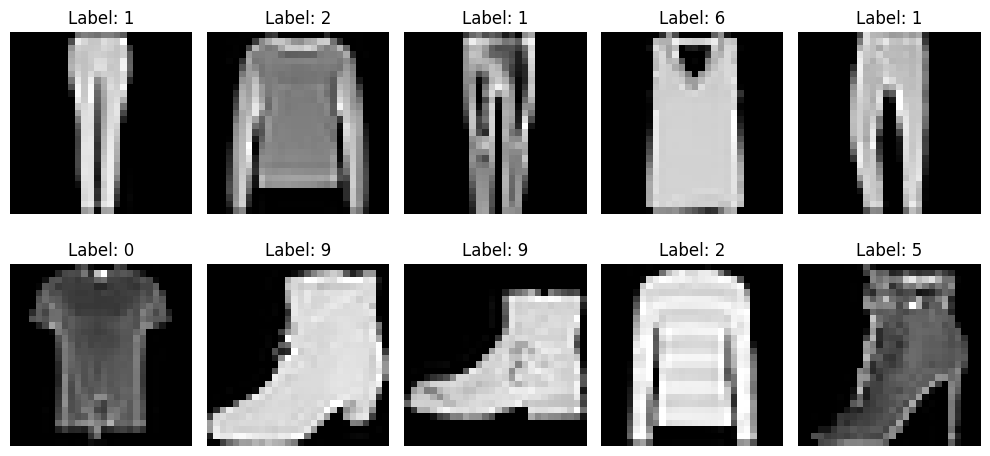

INFO:/content/data266-5937/hw7:Saved FashionMNIST sample visualization


In [10]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.tight_layout()

sample_path = HW_PATH / "fashionmnist_samples.png"
plt.savefig(sample_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

logger.info("Saved FashionMNIST sample visualization")

In [11]:
class FCAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)
        return reconstruction.view(-1, 1, 28, 28)

In [12]:
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def encode(self, x):
        hidden = self.encoder(x)
        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        standard_deviation = torch.exp(0.5 * logvar)
        random_noise = torch.randn_like(standard_deviation)
        return mu + random_noise * standard_deviation

    def decode(self, z):
        reconstruction = self.decoder(z)
        return reconstruction.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)

        return reconstruction, mu, logvar

In [13]:
def train_fc_autoencoder(model, loader, optimizer, epochs):
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for images, _ in loader:
            images = images.to(device, non_blocking=True)

            optimizer.zero_grad()

            reconstructions = model(images)
            loss = F.mse_loss(reconstructions, images)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(loader)
        history.append(average_loss)

        print(
            f"FC-AE Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {average_loss:.6f}"
        )

        logger.info(
            f"FC-AE epoch {epoch + 1}/{epochs}, "
            f"loss={average_loss:.6f}"
        )

    return history


def vae_loss_function(reconstruction, images, mu, logvar):
    reconstruction_loss = F.binary_cross_entropy(
        reconstruction,
        images,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = reconstruction_loss + kl_loss

    return (
        total_loss / images.size(0),
        reconstruction_loss / images.size(0),
        kl_loss / images.size(0)
    )


def train_vae(model, loader, optimizer, epochs):
    history = {
        "total_loss": [],
        "reconstruction_loss": [],
        "kl_loss": []
    }

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        total_reconstruction_loss = 0.0
        total_kl_loss = 0.0

        for images, _ in loader:
            images = images.to(device, non_blocking=True)

            optimizer.zero_grad()

            reconstructions, mu, logvar = model(images)

            loss, reconstruction_loss, kl_loss = vae_loss_function(
                reconstructions,
                images,
                mu,
                logvar
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            total_reconstruction_loss += reconstruction_loss.item()
            total_kl_loss += kl_loss.item()

        avg_total_loss = total_loss / len(loader)
        avg_reconstruction_loss = (
            total_reconstruction_loss / len(loader)
        )
        avg_kl_loss = total_kl_loss / len(loader)

        history["total_loss"].append(avg_total_loss)
        history["reconstruction_loss"].append(avg_reconstruction_loss)
        history["kl_loss"].append(avg_kl_loss)

        print(
            f"VAE Epoch [{epoch + 1}/{epochs}] "
            f"Total Loss: {avg_total_loss:.4f}, "
            f"Reconstruction Loss: {avg_reconstruction_loss:.4f}, "
            f"KL Loss: {avg_kl_loss:.4f}"
        )

        logger.info(
            f"VAE epoch {epoch + 1}/{epochs}, "
            f"total_loss={avg_total_loss:.4f}, "
            f"reconstruction_loss={avg_reconstruction_loss:.4f}, "
            f"kl_loss={avg_kl_loss:.4f}"
        )

    return history

In [14]:
!git status
!git add -A
!git commit -m "FC Autoencoder and VAE architecture set with defined metrics"
!git push origin main

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   hw7/RUN_LOG.txt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hw7/fashionmnist_samples.png

no changes added to commit (use "git add" and/or "git commit -a")
[main d7e7dc2] FC Autoencoder and VAE architecture set with defined metrics
 2 files changed, 1 insertion(+)
 create mode 100644 hw7/fashionmnist_samples.png
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 21.44 KiB | 10.72 MiB/s, done.
Total 5 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/vedika0806/data266-5937.git
   68f3b1c..d7e7dc2  main -> 

In [15]:
EPOCHS = 10
LATENT_DIM_FC = 64

fc_ae = FCAutoencoder(
    latent_dim=LATENT_DIM_FC
).to(device)

fc_optimizer = optim.Adam(
    fc_ae.parameters(),
    lr=1e-3
)

fc_start_time = time.time()

fc_history = train_fc_autoencoder(
    fc_ae,
    train_loader,
    fc_optimizer,
    EPOCHS
)

fc_training_time = time.time() - fc_start_time

print(f"FC-AE training time: {fc_training_time / 60:.2f} minutes")

torch.save(
    fc_ae.state_dict(),
    HW_PATH / "fc_autoencoder.pt"
)

logger.info("FC-AE training completed and model saved")

INFO:/content/data266-5937/hw7:FC-AE epoch 1/10, loss=0.037447


FC-AE Epoch [1/10] Loss: 0.037447


INFO:/content/data266-5937/hw7:FC-AE epoch 2/10, loss=0.020243


FC-AE Epoch [2/10] Loss: 0.020243


INFO:/content/data266-5937/hw7:FC-AE epoch 3/10, loss=0.017539


...

FC-AE Epoch [8/10] Loss: 0.012721


INFO:/content/data266-5937/hw7:FC-AE epoch 9/10, loss=0.012237


FC-AE Epoch [9/10] Loss: 0.012237


INFO:/content/data266-5937/hw7:FC-AE epoch 10/10, loss=0.011854
INFO:/content/data266-5937/hw7:FC-AE training completed and model saved


FC-AE Epoch [10/10] Loss: 0.011854
FC-AE training time: 1.18 minutes


In [16]:
LATENT_DIM_VAE = 16

vae = VAE(
    latent_dim=LATENT_DIM_VAE
).to(device)

vae_optimizer = optim.Adam(
    vae.parameters(),
    lr=1e-3
)

vae_start_time = time.time()

vae_history = train_vae(
    vae,
    train_loader,
    vae_optimizer,
    EPOCHS
)

vae_training_time = time.time() - vae_start_time

print(f"VAE training time: {vae_training_time / 60:.2f} minutes")

torch.save(
    vae.state_dict(),
    HW_PATH / "vae.pt"
)

logger.info("VAE training completed and model saved")

INFO:/content/data266-5937/hw7:VAE epoch 1/10, total_loss=292.1878, reconstruction_loss=278.4622, kl_loss=13.7256


VAE Epoch [1/10] Total Loss: 292.1878, Reconstruction Loss: 278.4622, KL Loss: 13.7256


INFO:/content/data266-5937/hw7:VAE epoch 2/10, total_loss=258.1138, reconstruction_loss=242.8747, kl_loss=15.2391


VAE Epoch [2/10] Total Loss: 258.1138, Reconstruction Loss: 242.8747, KL Loss: 15.2391


INFO:/content/data266-5937/hw7:VAE epoch 3/10, total_loss=252.0489, reconstruction_loss=236.5475, kl_loss=15.5014


...

VAE Epoch [8/10] Total Loss: 244.7212, Reconstruction Loss: 228.7693, KL Loss: 15.9519


INFO:/content/data266-5937/hw7:VAE epoch 9/10, total_loss=244.2221, reconstruction_loss=228.2130, kl_loss=16.0091


VAE Epoch [9/10] Total Loss: 244.2221, Reconstruction Loss: 228.2130, KL Loss: 16.0091


INFO:/content/data266-5937/hw7:VAE epoch 10/10, total_loss=243.7261, reconstruction_loss=227.7136, kl_loss=16.0125
INFO:/content/data266-5937/hw7:VAE training completed and model saved


VAE Epoch [10/10] Total Loss: 243.7261, Reconstruction Loss: 227.7136, KL Loss: 16.0125
VAE training time: 1.19 minutes


In [17]:
!git status
!git add -A
!git commit -m "Training completed for FC AE and VAE"
!git push origin main

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   hw7/RUN_LOG.txt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hw7/fc_autoencoder.pt
	hw7/vae.pt

no changes added to commit (use "git add" and/or "git commit -a")
[main 66cc89f] Training completed for FC AE and VAE
 3 files changed, 22 insertions(+)
 create mode 100644 hw7/fc_autoencoder.pt
 create mode 100644 hw7/vae.pt
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 3.20 MiB | 6.23 MiB/s, done.
Total 6 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/vedika0806/data266-5937.git
   d7e7dc2..66cc89f  main

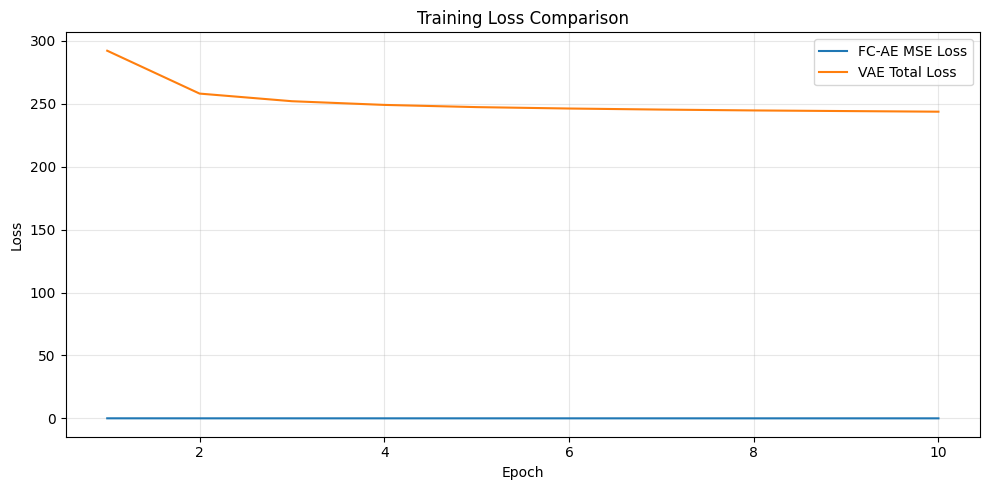

INFO:/content/data266-5937/hw7:Saved training loss comparison plot


In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    fc_history,
    label="FC-AE MSE Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    vae_history["total_loss"],
    label="VAE Total Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

loss_plot_path = HW_PATH / "training_loss_comparison.png"
plt.savefig(loss_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

logger.info("Saved training loss comparison plot")

In [19]:
def evaluate_fc_autoencoder(model, loader):
    model.eval()

    total_squared_error = 0.0
    total_pixels = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)

            reconstructions = model(images)

            total_squared_error += F.mse_loss(
                reconstructions,
                images,
                reduction="sum"
            ).item()

            total_pixels += images.numel()

    return total_squared_error / total_pixels


fc_test_mse = evaluate_fc_autoencoder(
    fc_ae,
    test_loader
)

print(f"FC-AE Test MSE: {fc_test_mse:.6f}")

logger.info(f"FC-AE test MSE: {fc_test_mse:.6f}")

INFO:/content/data266-5937/hw7:FC-AE test MSE: 0.011885


FC-AE Test MSE: 0.011885


In [20]:
def evaluate_vae(model, loader):
    model.eval()

    total_mse = 0.0
    total_pixels = 0
    total_kl = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)

            mu, logvar = model.encode(images)

            # Use the mean vector for deterministic evaluation
            reconstructions = model.decode(mu)

            total_mse += F.mse_loss(
                reconstructions,
                images,
                reduction="sum"
            ).item()

            total_pixels += images.numel()

            kl_loss = -0.5 * torch.sum(
                1 + logvar - mu.pow(2) - logvar.exp()
            )

            total_kl += kl_loss.item()
            total_samples += images.size(0)

    test_mse = total_mse / total_pixels
    average_kl = total_kl / total_samples

    return test_mse, average_kl


vae_test_mse, vae_test_kl = evaluate_vae(
    vae,
    test_loader
)

print(f"VAE Test MSE: {vae_test_mse:.6f}")
print(f"VAE Average KL Loss: {vae_test_kl:.6f}")

logger.info(f"VAE test MSE: {vae_test_mse:.6f}")
logger.info(f"VAE average KL loss: {vae_test_kl:.6f}")

INFO:/content/data266-5937/hw7:VAE test MSE: 0.014056
INFO:/content/data266-5937/hw7:VAE average KL loss: 16.241899


VAE Test MSE: 0.014056
VAE Average KL Loss: 16.241899


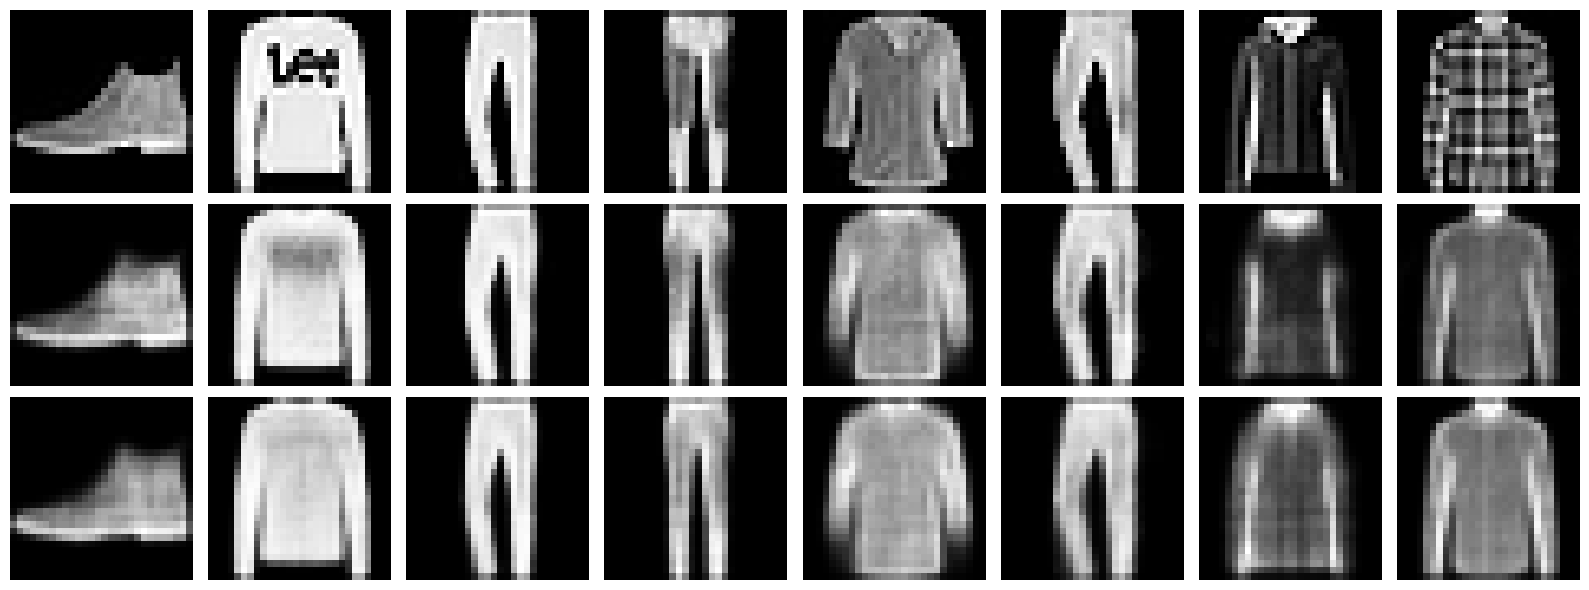

INFO:/content/data266-5937/hw7:Saved reconstruction comparison


In [21]:
fc_ae.eval()
vae.eval()

images, _ = next(iter(test_loader))
images = images[:8].to(device)

with torch.no_grad():
    fc_reconstructions = fc_ae(images)

    vae_mu, vae_logvar = vae.encode(images)
    vae_reconstructions = vae.decode(vae_mu)

fig, axes = plt.subplots(3, 8, figsize=(16, 6))

for i in range(8):
    axes[0, i].imshow(images[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        fc_reconstructions[i].cpu().squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

    axes[2, i].imshow(
        vae_reconstructions[i].cpu().squeeze(),
        cmap="gray"
    )
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("FC-AE", fontsize=12)
axes[2, 0].set_ylabel("VAE", fontsize=12)

plt.tight_layout()

reconstruction_path = HW_PATH / "reconstruction_comparison.png"
plt.savefig(reconstruction_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

logger.info("Saved reconstruction comparison")

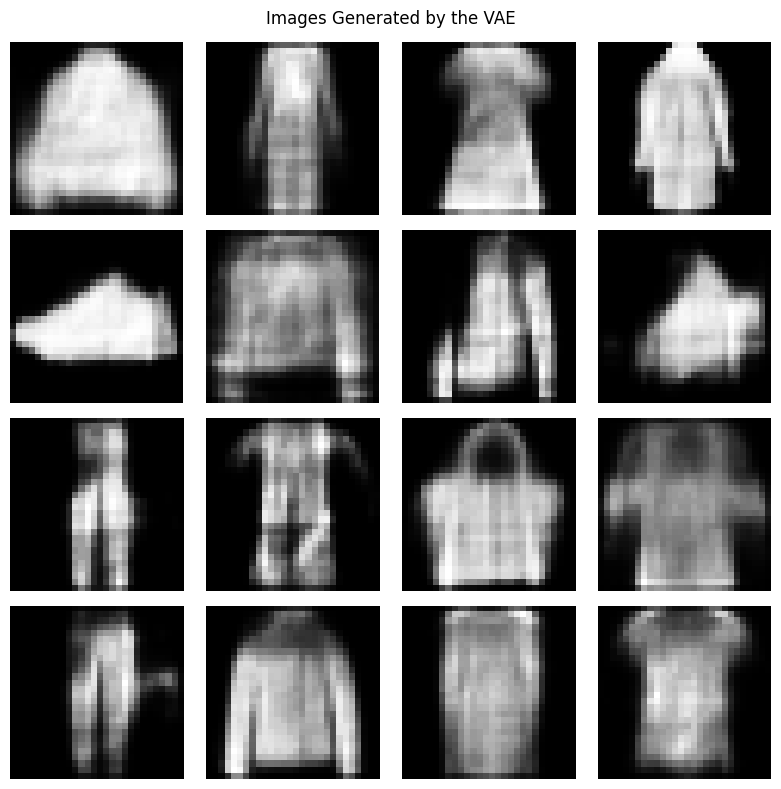

INFO:/content/data266-5937/hw7:Saved VAE-generated sample images


In [22]:
vae.eval()

with torch.no_grad():
    random_latent_vectors = torch.randn(
        16,
        LATENT_DIM_VAE,
        device=device
    )

    generated_images = vae.decode(random_latent_vectors)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        generated_images[i].cpu().squeeze(),
        cmap="gray"
    )
    plt.axis("off")

plt.suptitle("Images Generated by the VAE")
plt.tight_layout()

generated_path = HW_PATH / "vae_generated_samples.png"
plt.savefig(generated_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

logger.info("Saved VAE-generated sample images")

In [23]:
metrics_section = f"""
## HW7: FashionMNIST Autoencoders

### Model Configuration

- Dataset: FashionMNIST
- FC-AE latent dimension: {LATENT_DIM_FC}
- VAE latent dimension: {LATENT_DIM_VAE}
- Batch size: {BATCH_SIZE}
- Epochs: {EPOCHS}
- Optimizer: Adam
- Learning rate: 0.001
- Device: {device}

### Results

| Model | Test MSE | Additional Metric |
|---|---:|---:|
| FC-AE | {fc_test_mse:.6f} | Training time: {fc_training_time / 60:.2f} minutes |
| VAE | {vae_test_mse:.6f} | Average KL loss: {vae_test_kl:.6f} |

The FC-AE was evaluated using reconstruction mean squared error. The VAE was evaluated using deterministic reconstruction from the mean latent vector. The VAE also includes KL divergence to measure how closely its latent distribution follows the standard normal distribution.

"""

metrics_path = HW_PATH / "METRICS.md"

existing_content = (
    metrics_path.read_text()
    if metrics_path.exists()
    else ""
)

if "## HW7: FashionMNIST Autoencoders" not in existing_content:
    with open(metrics_path, "a") as f:
        f.write(metrics_section)
    print("Metrics added to METRICS.md")
else:
    print("HW7 metrics already exist; no duplicate section added.")

logger.info("Updated METRICS.md")

INFO:/content/data266-5937/hw7:Updated METRICS.md


Metrics added to METRICS.md


In [24]:
!git status
!git add -A
!git commit -m "Results & metrics file updated"
!git push origin main

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   hw7/RUN_LOG.txt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hw7/METRICS.md
	hw7/reconstruction_comparison.png
	hw7/training_loss_comparison.png
	hw7/vae_generated_samples.png

no changes added to commit (use "git add" and/or "git commit -a")
[main 26b237b] Results & metrics file updated
 5 files changed, 30 insertions(+)
 create mode 100644 hw7/METRICS.md
 create mode 100644 hw7/reconstruction_comparison.png
 create mode 100644 hw7/training_loss_comparison.png
 create mode 100644 hw7/vae_generated_samples.png
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 99.30 KiB | 14.19 MiB/s, done

In [25]:
ai_use_content = """
# AI_USE.md

## How AI was used?

AI assistance was used to help understand the structure of the autoencoder & VAE, and troubleshoot code during development. The final implementation was run and tested in Google Colab.

## Any specific problem encountered?

AI initially described these results as good based mainly on the numerical metrics. However, after I inspected the reconstructed images, I noticed that they were blurry and did not reproduce the original clothing images very well.

## How I identified the problem

The numerical MSE value alone did not fully represent the visual quality of the reconstructions. By comparing the original FashionMNIST images with the reconstructed images, I noticed that important details and shapes were missing.

## What I changed
I learned that increasing the number of training epochs, increasing the VAE latent dimension, and reducing the weight of the KL-divergence term can help give more solid and good reconstructed images.

"""

ai_use_path = HW_PATH / "AI_USE.md"

if not ai_use_path.exists():
    ai_use_path.write_text(ai_use_content)
    print("AI_USE.md created.")
else:
    print("AI_USE.md already exists.")

logger.info("Checked AI_USE.md")

INFO:/content/data266-5937/hw7:Checked AI_USE.md


AI_USE.md created.


In [26]:
!git status
!git add -A
!git commit -m "AI_USE file updated"
!git push origin main

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   hw7/RUN_LOG.txt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hw7/AI_USE.md

no changes added to commit (use "git add" and/or "git commit -a")
[main 67a2ffd] AI_USE file updated
 2 files changed, 19 insertions(+)
 create mode 100644 hw7/AI_USE.md
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 965 bytes | 965.00 KiB/s, done.
Total 5 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/vedika0806/data266-5937.git
   26b237b..67a2ffd  main -> main


In [ ]:
import json
import subprocess
from google.colab import _message

response = _message.blocking_request("get_ipynb")
notebook_data = response["ipynb"]

notebook_path = REPO_PATH / "hw7" / "HW7_DATA266_5937.ipynb"

with open(notebook_path, "w") as f:
    json.dump(notebook_data, f, indent=2)

print(f"Notebook saved to: {notebook_path}")

subprocess.run(
    ["git", "-C", str(REPO_PATH), "add", "hw7/HW7_DATA266_5937.ipynb"],
    check=True
)

subprocess.run(
    [
        "git",
        "-C",
        str(REPO_PATH),
        "commit",
        "-m",
        "hw7: add Colab notebook"
    ],
    check=True
)

subprocess.run(
    ["git", "-C", str(REPO_PATH), "push", "origin", "main"],
    check=True
)

print("Notebook committed and pushed successfully.")